Write a program to implement
the local binary pattern on gray scale
image.
● Write a program to denoise the input image corrupted by Gaussian and
Speckle noise by using following filters (3x3 or 5x5 window).
(a) Weiner filter
(b) Median filtering
(c) Gaussian filter
(d) Bilateral filter

Saving Spider Lily.jpeg to Spider Lily.jpeg
Image loaded successfully.
Image size: (1307, 736)


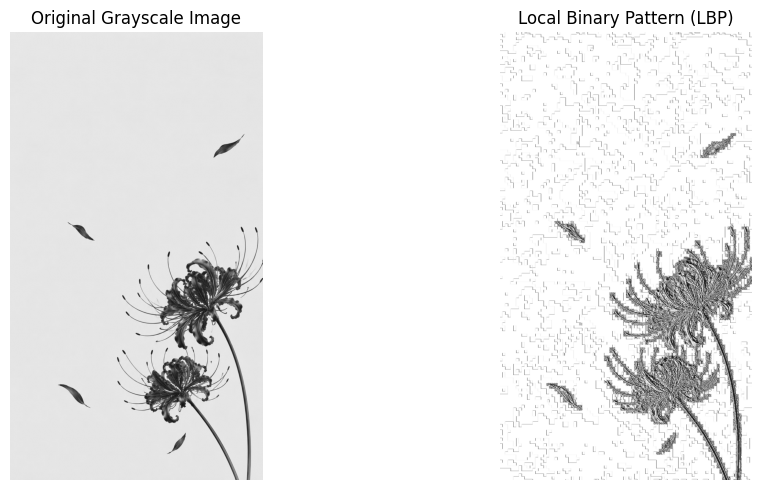

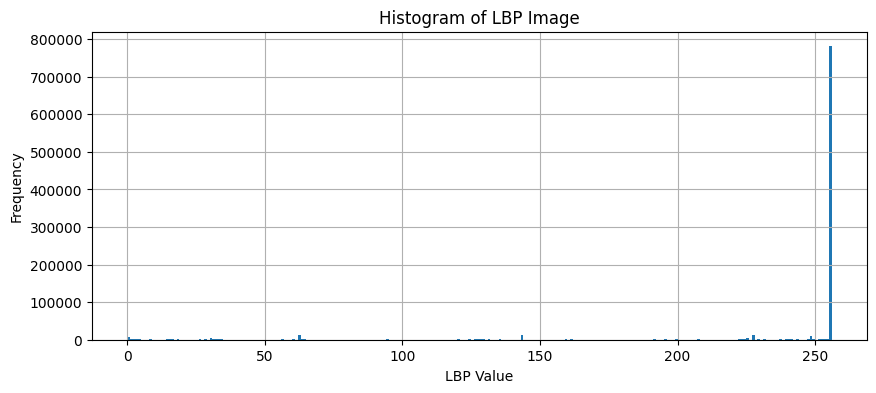

In [1]:
# ============================================================
# LOCAL BINARY PATTERN (LBP)
# ============================================================

import cv2
import numpy as np
import matplotlib.pyplot as plt

# Upload image in Google Colab
from google.colab import files

uploaded = files.upload()

# Read image
filename = next(iter(uploaded))

image = cv2.imread(filename, cv2.IMREAD_GRAYSCALE)

if image is None:
    print("Error: Image could not be loaded.")
else:
    print("Image loaded successfully.")
    print("Image size:", image.shape)


# ============================================================
# LBP FUNCTION
# ============================================================

def calculate_lbp(image):
    rows, cols = image.shape

    # LBP image
    lbp = np.zeros((rows - 2, cols - 2), dtype=np.uint8)

    # 8 neighboring pixels
    neighbors = [
        (-1, -1),  # top-left
        (-1,  0),  # top
        (-1,  1),  # top-right
        ( 0,  1),  # right
        ( 1,  1),  # bottom-right
        ( 1,  0),  # bottom
        ( 1, -1),  # bottom-left
        ( 0, -1)   # left
    ]

    for i in range(1, rows - 1):
        for j in range(1, cols - 1):

            center = image[i, j]

            binary_value = 0

            for k, (di, dj) in enumerate(neighbors):

                neighbor = image[i + di, j + dj]

                if neighbor >= center:
                    binary_value += (1 << k)

            lbp[i - 1, j - 1] = binary_value

    return lbp


# Calculate LBP
lbp_image = calculate_lbp(image)


# ============================================================
# DISPLAY ORIGINAL AND LBP
# ============================================================

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(image, cmap='gray')
plt.title("Original Grayscale Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(lbp_image, cmap='gray')
plt.title("Local Binary Pattern (LBP)")
plt.axis("off")

plt.tight_layout()
plt.show()


# ============================================================
# LBP HISTOGRAM
# ============================================================

plt.figure(figsize=(10, 4))

plt.hist(
    lbp_image.ravel(),
    bins=256,
    range=(0, 256)
)

plt.title("Histogram of LBP Image")
plt.xlabel("LBP Value")
plt.ylabel("Frequency")
plt.grid(True)

plt.show()

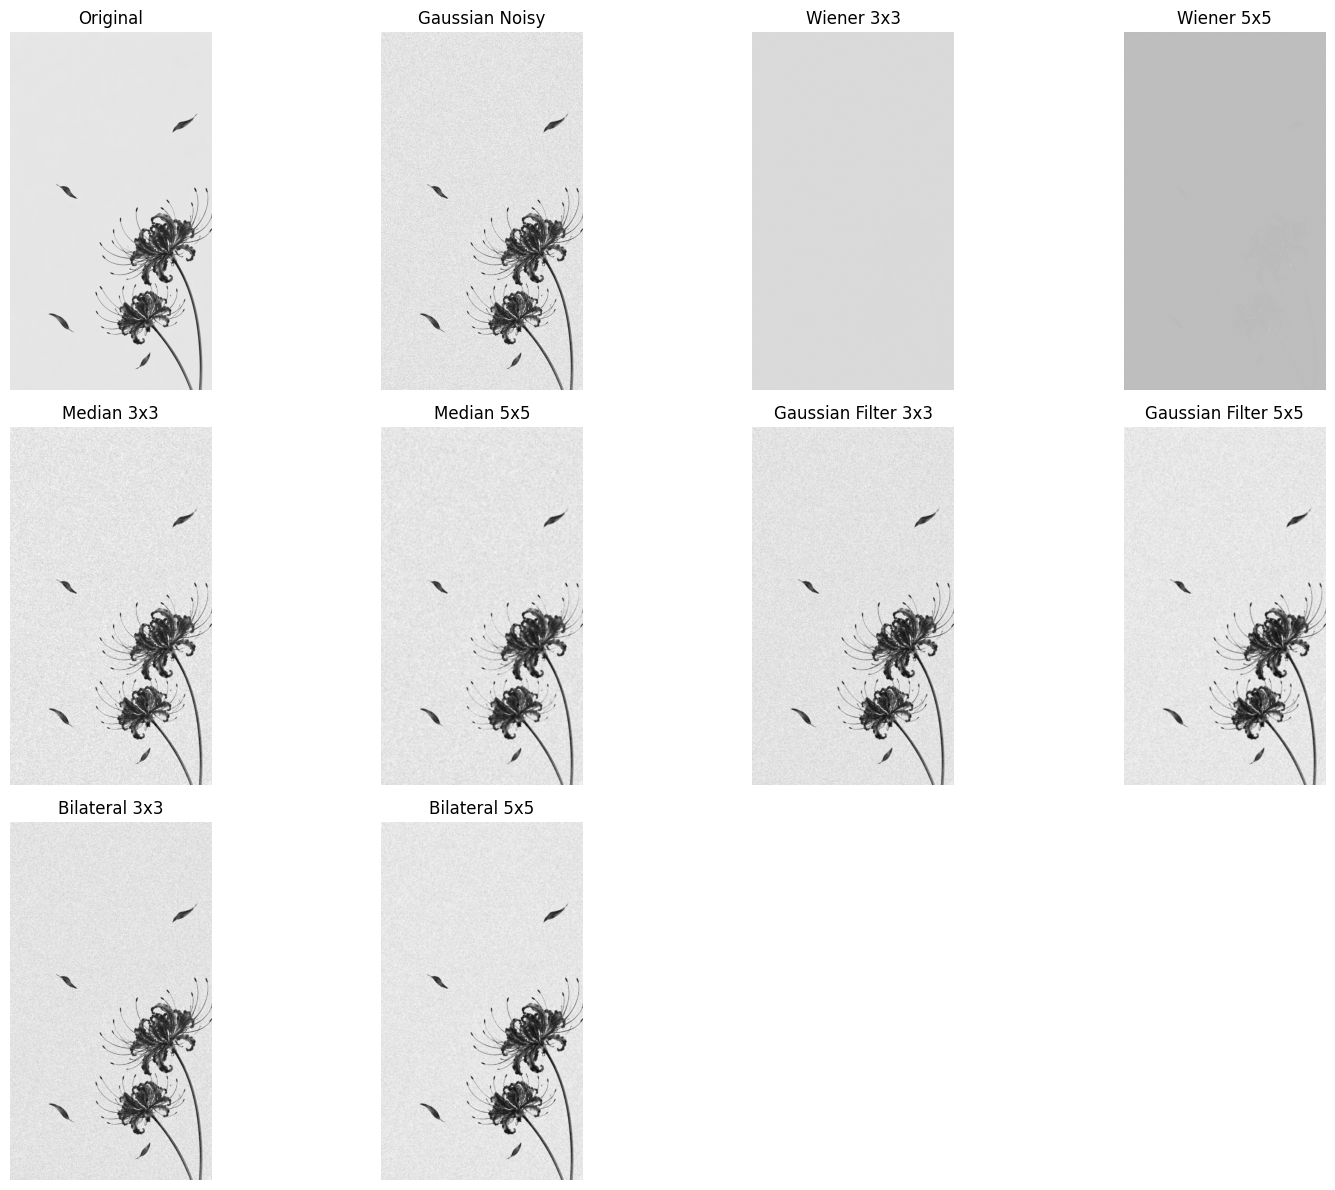

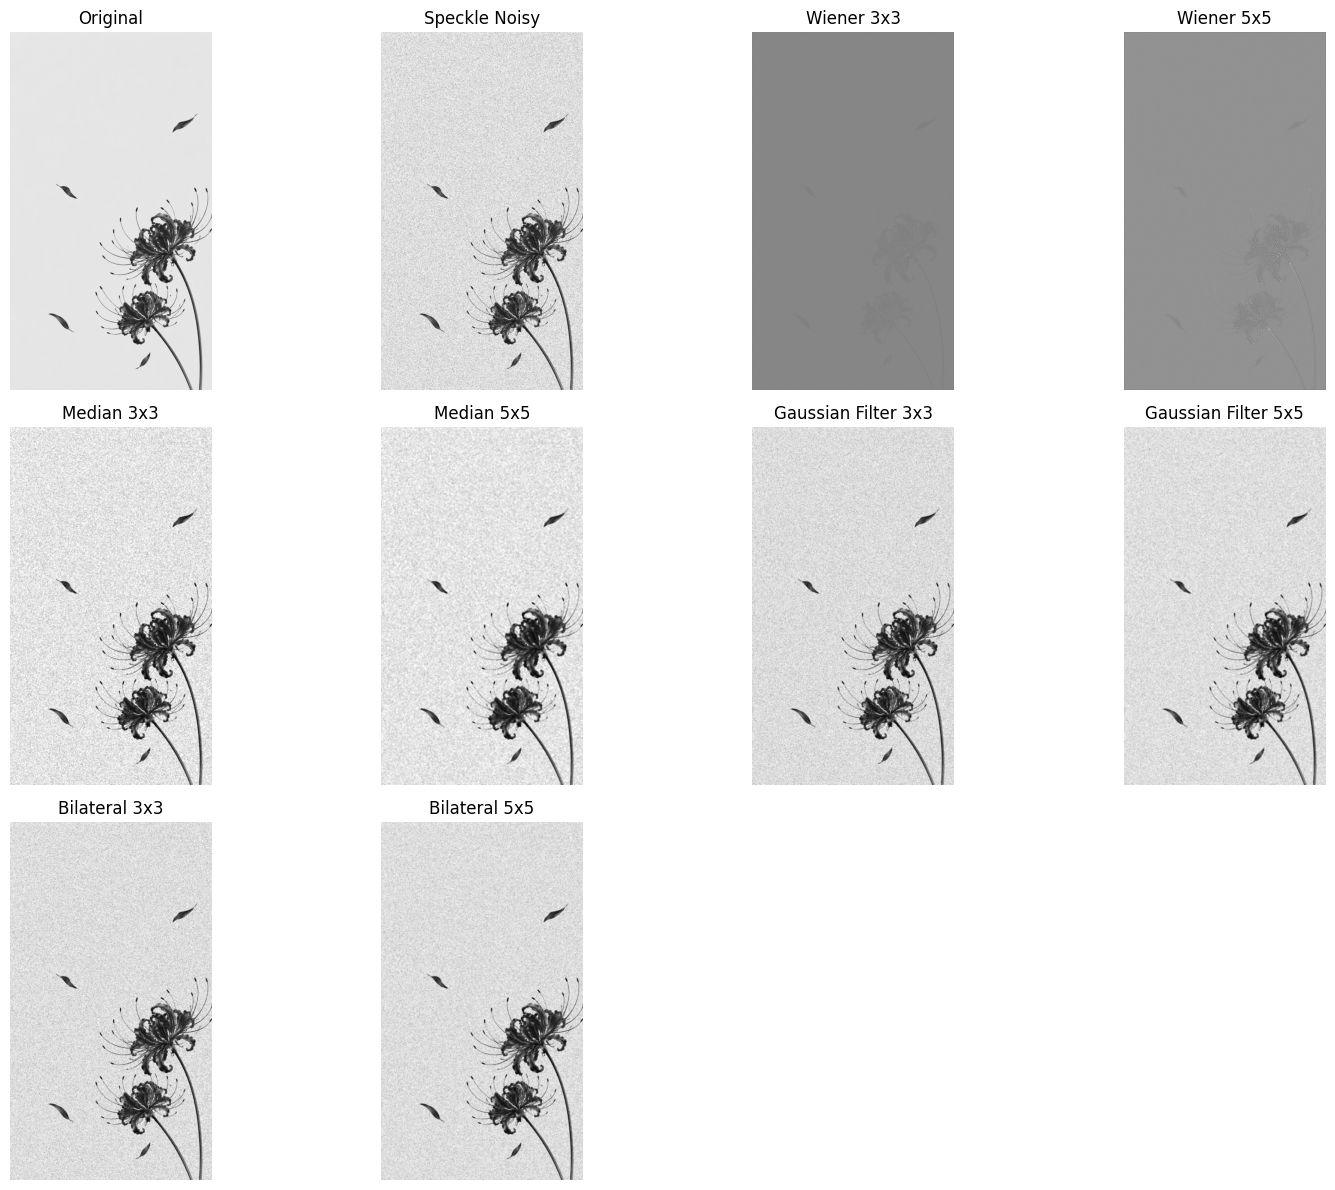

In [2]:
# ============================================================
# IMAGE DENOISING USING DIFFERENT FILTERS
# ============================================================

import cv2
import numpy as np
import matplotlib.pyplot as plt

from scipy.signal import wiener
from skimage.util import random_noise


# ============================================================
# READ IMAGE
# ============================================================

# If image is already loaded from the previous program,
# this line can be skipped.

image = cv2.imread(filename, cv2.IMREAD_GRAYSCALE)

# Convert image to float [0,1]
image_float = image.astype(np.float32) / 255.0


# ============================================================
# ADD GAUSSIAN NOISE
# ============================================================

gaussian_noisy = random_noise(
    image_float,
    mode='gaussian',
    mean=0,
    var=0.01
)

gaussian_noisy = np.clip(
    gaussian_noisy * 255,
    0,
    255
).astype(np.uint8)


# ============================================================
# ADD SPECKLE NOISE
# ============================================================

speckle_noisy = random_noise(
    image_float,
    mode='speckle',
    mean=0,
    var=0.04
)

speckle_noisy = np.clip(
    speckle_noisy * 255,
    0,
    255
).astype(np.uint8)


# ============================================================
# WIENER FILTER
# ============================================================

# 3x3 Wiener
wiener_gaussian_3 = wiener(
    gaussian_noisy,
    (3, 3)
)

wiener_speckle_3 = wiener(
    speckle_noisy,
    (3, 3)
)

# 5x5 Wiener
wiener_gaussian_5 = wiener(
    gaussian_noisy,
    (5, 5)
)

wiener_speckle_5 = wiener(
    speckle_noisy,
    (5, 5)
)


# ============================================================
# MEDIAN FILTER
# ============================================================

# 3x3
median_gaussian_3 = cv2.medianBlur(
    gaussian_noisy,
    3
)

median_speckle_3 = cv2.medianBlur(
    speckle_noisy,
    3
)

# 5x5
median_gaussian_5 = cv2.medianBlur(
    gaussian_noisy,
    5
)

median_speckle_5 = cv2.medianBlur(
    speckle_noisy,
    5
)


# ============================================================
# GAUSSIAN FILTER
# ============================================================

# 3x3
gaussian_filter_gaussian_3 = cv2.GaussianBlur(
    gaussian_noisy,
    (3, 3),
    0
)

gaussian_filter_speckle_3 = cv2.GaussianBlur(
    speckle_noisy,
    (3, 3),
    0
)

# 5x5
gaussian_filter_gaussian_5 = cv2.GaussianBlur(
    gaussian_noisy,
    (5, 5),
    0
)

gaussian_filter_speckle_5 = cv2.GaussianBlur(
    speckle_noisy,
    (5, 5),
    0
)


# ============================================================
# BILATERAL FILTER
# ============================================================

# 3x3
bilateral_gaussian_3 = cv2.bilateralFilter(
    gaussian_noisy,
    3,
    75,
    75
)

bilateral_speckle_3 = cv2.bilateralFilter(
    speckle_noisy,
    3,
    75,
    75
)

# 5x5
bilateral_gaussian_5 = cv2.bilateralFilter(
    gaussian_noisy,
    5,
    75,
    75
)

bilateral_speckle_5 = cv2.bilateralFilter(
    speckle_noisy,
    5,
    75,
    75
)


# ============================================================
# DISPLAY GAUSSIAN NOISE RESULTS
# ============================================================

plt.figure(figsize=(15, 12))

plt.subplot(3, 4, 1)
plt.imshow(image, cmap='gray')
plt.title("Original")
plt.axis("off")

plt.subplot(3, 4, 2)
plt.imshow(gaussian_noisy, cmap='gray')
plt.title("Gaussian Noisy")
plt.axis("off")

plt.subplot(3, 4, 3)
plt.imshow(wiener_gaussian_3, cmap='gray')
plt.title("Wiener 3x3")
plt.axis("off")

plt.subplot(3, 4, 4)
plt.imshow(wiener_gaussian_5, cmap='gray')
plt.title("Wiener 5x5")
plt.axis("off")

plt.subplot(3, 4, 5)
plt.imshow(median_gaussian_3, cmap='gray')
plt.title("Median 3x3")
plt.axis("off")

plt.subplot(3, 4, 6)
plt.imshow(median_gaussian_5, cmap='gray')
plt.title("Median 5x5")
plt.axis("off")

plt.subplot(3, 4, 7)
plt.imshow(gaussian_filter_gaussian_3, cmap='gray')
plt.title("Gaussian Filter 3x3")
plt.axis("off")

plt.subplot(3, 4, 8)
plt.imshow(gaussian_filter_gaussian_5, cmap='gray')
plt.title("Gaussian Filter 5x5")
plt.axis("off")

plt.subplot(3, 4, 9)
plt.imshow(bilateral_gaussian_3, cmap='gray')
plt.title("Bilateral 3x3")
plt.axis("off")

plt.subplot(3, 4, 10)
plt.imshow(bilateral_gaussian_5, cmap='gray')
plt.title("Bilateral 5x5")
plt.axis("off")

plt.tight_layout()
plt.show()


# ============================================================
# DISPLAY SPECKLE NOISE RESULTS
# ============================================================

plt.figure(figsize=(15, 12))

plt.subplot(3, 4, 1)
plt.imshow(image, cmap='gray')
plt.title("Original")
plt.axis("off")

plt.subplot(3, 4, 2)
plt.imshow(speckle_noisy, cmap='gray')
plt.title("Speckle Noisy")
plt.axis("off")

plt.subplot(3, 4, 3)
plt.imshow(wiener_speckle_3, cmap='gray')
plt.title("Wiener 3x3")
plt.axis("off")

plt.subplot(3, 4, 4)
plt.imshow(wiener_speckle_5, cmap='gray')
plt.title("Wiener 5x5")
plt.axis("off")

plt.subplot(3, 4, 5)
plt.imshow(median_speckle_3, cmap='gray')
plt.title("Median 3x3")
plt.axis("off")

plt.subplot(3, 4, 6)
plt.imshow(median_speckle_5, cmap='gray')
plt.title("Median 5x5")
plt.axis("off")

plt.subplot(3, 4, 7)
plt.imshow(gaussian_filter_speckle_3, cmap='gray')
plt.title("Gaussian Filter 3x3")
plt.axis("off")

plt.subplot(3, 4, 8)
plt.imshow(gaussian_filter_speckle_5, cmap='gray')
plt.title("Gaussian Filter 5x5")
plt.axis("off")

plt.subplot(3, 4, 9)
plt.imshow(bilateral_speckle_3, cmap='gray')
plt.title("Bilateral 3x3")
plt.axis("off")

plt.subplot(3, 4, 10)
plt.imshow(bilateral_speckle_5, cmap='gray')
plt.title("Bilateral 5x5")
plt.axis("off")

plt.tight_layout()
plt.show()

In [3]:
# ============================================================
# MSE AND PSNR
# ============================================================

def mse(original, restored):
    original = original.astype(np.float32)
    restored = restored.astype(np.float32)

    return np.mean(
        (original - restored) ** 2
    )


def psnr(original, restored):
    error = mse(original, restored)

    if error == 0:
        return float('inf')

    return 10 * np.log10(
        (255 ** 2) / error
    )


# Store results
results = {
    "Wiener 3x3 - Gaussian": wiener_gaussian_3,
    "Wiener 5x5 - Gaussian": wiener_gaussian_5,

    "Median 3x3 - Gaussian": median_gaussian_3,
    "Median 5x5 - Gaussian": median_gaussian_5,

    "Gaussian 3x3 - Gaussian": gaussian_filter_gaussian_3,
    "Gaussian 5x5 - Gaussian": gaussian_filter_gaussian_5,

    "Bilateral 3x3 - Gaussian": bilateral_gaussian_3,
    "Bilateral 5x5 - Gaussian": bilateral_gaussian_5,

    "Wiener 3x3 - Speckle": wiener_speckle_3,
    "Wiener 5x5 - Speckle": wiener_speckle_5,

    "Median 3x3 - Speckle": median_speckle_3,
    "Median 5x5 - Speckle": median_speckle_5,

    "Gaussian 3x3 - Speckle": gaussian_filter_speckle_3,
    "Gaussian 5x5 - Speckle": gaussian_filter_speckle_5,

    "Bilateral 3x3 - Speckle": bilateral_speckle_3,
    "Bilateral 5x5 - Speckle": bilateral_speckle_5
}


print("=" * 60)
print("FILTER PERFORMANCE")
print("=" * 60)

for name, result in results.items():

    print("\n", name)

    print(
        "MSE  :",
        round(mse(image, result), 4)
    )

    print(
        "PSNR :",
        round(psnr(image, result), 4),
        "dB"
    )

FILTER PERFORMANCE

 Wiener 3x3 - Gaussian
MSE  : 31069.127
PSNR : 3.2075 dB

 Wiener 5x5 - Gaussian
MSE  : 12601.051
PSNR : 7.1267 dB

 Median 3x3 - Gaussian
MSE  : 142.4001
PSNR : 26.5957 dB

 Median 5x5 - Gaussian
MSE  : 138.891
PSNR : 26.7041 dB

 Gaussian 3x3 - Gaussian
MSE  : 110.5235
PSNR : 27.6963 dB

 Gaussian 5x5 - Gaussian
MSE  : 107.2811
PSNR : 27.8256 dB

 Bilateral 3x3 - Gaussian
MSE  : 130.3528
PSNR : 26.9796 dB

 Bilateral 5x5 - Gaussian
MSE  : 77.0985
PSNR : 29.2603 dB

 Wiener 3x3 - Speckle
MSE  : 3860.2056
PSNR : 12.2647 dB

 Wiener 5x5 - Speckle
MSE  : 4400.672
PSNR : 11.6956 dB

 Median 3x3 - Speckle
MSE  : 325.8474
PSNR : 23.0007 dB

 Median 5x5 - Speckle
MSE  : 221.8686
PSNR : 24.6698 dB

 Gaussian 3x3 - Speckle
MSE  : 269.4693
PSNR : 23.8257 dB

 Gaussian 5x5 - Speckle
MSE  : 223.7824
PSNR : 24.6325 dB

 Bilateral 3x3 - Speckle
MSE  : 388.429
PSNR : 22.2377 dB

 Bilateral 5x5 - Speckle
MSE  : 231.4878
PSNR : 24.4855 dB
